# Lab 5 — Single-motor parameter identification

**Source:** your uploaded `motor_single_voltage.txt`. **Scope:** one motor (M4/E4), following your selected configuration. **Provenance:** treated as the 2D simulator run discussed in this session; physical robot acquisition has not been confirmed. The 11.2 V value was configured in the collector, not measured independently. Consequently, fitted constants describe this run and its assumed voltage scale, not a verified physical motor.

The [course assignment](https://github.com/NewUU-engineering/Robotics-course/tree/main/05_Motor_parameter_identification) specifies parameter tables, a voltage–speed fit with a dead-zone assessment, a simulated step-response comparison, and a short discussion. Your [w5 README](https://github.com/hvsniddin/robotics-course/tree/master/w5) records a permitted single-wheel scope. This notebook follows that scope; it cannot compare two wheels.

**Run all cells in Colab or Jupyter.** The original data are embedded byte-for-byte, so no upload is needed. Set `DATA_PATH` below only to analyze another file. Appended runs remain separate: the final run is selected by default, and coverage is checked before fitting.


In [2]:
import base64, hashlib, io
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.integrate import solve_ivp

DATA_PATH = "motor_single_voltage.txt"  # Optional: path to a replacement TXT file.
RUN_INDEX = -1    # Last run; use 0 for the first run.
EMBEDDED = "..."
raw = Path(DATA_PATH).read_bytes() if DATA_PATH else base64.b64decode(EMBEDDED)
print("Source SHA-256:", hashlib.sha256(raw).hexdigest())
runs, current = [], []
for line in raw.decode('utf-8-sig').splitlines():
    if line.startswith('# NEW RUN'):
        if current: runs.append(current)
        current = []
    elif line.strip() and not line.startswith('#'):
        current.append([float(v) for v in line.split(',')])
if current: runs.append(current)
a = np.asarray(runs[RUN_INDEX])
assert a.ndim == 2 and a.shape[1] == 5 and np.isfinite(a).all()
df = pd.DataFrame(a, columns=['PWM','Battery_V','Voltage_V','Time_ms','Angle_deg'])
expected = set(range(-100, 101, 5))
assert set(df.PWM) == expected, "Incomplete PWM coverage: finish collection before analysis."
assert np.allclose(df.Voltage_V, df.PWM * df.Battery_V / 100)
assert not df.duplicated(['PWM','Time_ms']).any(), "Duplicate timestamps or combined runs."
for pwm,g in df.groupby('PWM'):
    assert (np.diff(g.Time_ms)>0).all() and g.Time_ms.min()>=0
print(f"Runs found: {len(runs)}; selected: {RUN_INDEX}; readings: {len(df)}; PWM levels: {df.PWM.nunique()}")
print("Configured supply values (V):", sorted(df.Battery_V.unique()))


Source SHA-256: 11b1670ddd937541df0f315f90ad7a4e1b2552a669adf40e5bc078c2305c968b
Runs found: 1; selected: -1; readings: 2971; PWM levels: 41
Configured supply values (V): [np.float64(11.2)]


## 1. Model: what the two fitted parameters mean

A first-order motor model is $T_m\,d\omega/dt+\omega=\omega_{ss}$ for a constant input from rest. The difference between current and final speed drives acceleration: a large gap means faster acceleration, and the gap shrinks as speed approaches its final value. Solving gives $\omega(t)=\omega_{ss}(1-e^{-t/T_m})$; integrating speed gives the measured angle:

$$\theta(t)=\omega_{ss}[t-T_m+T_m e^{-t/T_m}].$$

The curve's final slope is **steady speed** $\omega_{ss}$, and its initial bend reveals **time constant** $T_m$. At one time constant, speed reaches about 63% of its final value. We fit angle directly to avoid amplifying encoder quantization by differentiating it.

Convert milliseconds to seconds and degrees to radians. Preserve the recorded step-relative time and encoder-reset angle; subtracting the first sample would remove part of the acceleration. This assumes the collector resets the encoder and timer for every power step. Runs with at most 1° angle range are treated as no resolved motion: their time constant cannot be identified.


In [3]:
def angle_model(t, speed, tau):
    return speed * (t + tau * np.expm1(-t/tau))

rows, traces = [], {}
for pwm,g in df.groupby('PWM', sort=True):
    t = g.Time_ms.to_numpy()/1000
    theta = np.deg2rad(g.Angle_deg.to_numpy())
    assert len(t)>=10 and t[-1]>=1.9, f"Too little data at PWM {pwm}"
    if np.ptp(g.Angle_deg)<=1:
        speed,tau,status = 0.,np.nan,'no resolved motion'
        predicted = np.zeros_like(theta)
    else:
        guess = np.polyfit(t[len(t)//2:],theta[len(t)//2:],1)[0]
        (speed,tau),_ = curve_fit(angle_model,t,theta,p0=[guess,.1],
            bounds=([-np.inf,.001],[np.inf,2.0]),maxfev=20000)
        status = 'bound reached' if tau<=.00101 or tau>=1.999 else 'fit'
        predicted = angle_model(t,speed,tau)
    rows.append(dict(PWM=int(pwm),Voltage_V=g.Voltage_V.mean(),
        omega_ss_rad_s=speed,T_m_s=tau,RMSE_rad=np.sqrt(np.mean((theta-predicted)**2)),
        Samples=len(t),End_s=t[-1],Median_dt_ms=np.median(np.diff(t))*1000,Status=status))
    traces[int(pwm)] = (t,theta)
results = pd.DataFrame(rows)
print(results.round(5).to_string(index=False,na_rep='N/A'))
print("\nMedian sampling intervals range (ms):", results.Median_dt_ms.min(), results.Median_dt_ms.max())
print("N/A means unidentifiable, not zero.")


 PWM  Voltage_V  omega_ss_rad_s   T_m_s  RMSE_rad  Samples   End_s  Median_dt_ms             Status
-100     -11.20       -13.04616 0.05803   0.05270       71 2.02506      27.25439                fit
 -95     -10.64       -12.90675 0.11573   0.07118       70 2.00221      27.20337                fit
 -90     -10.08       -10.93864 0.10820   0.13381       71 2.01674      27.25171                fit
 -85      -9.52       -11.02540 0.19016   0.05557       67 2.01519      28.27100                fit
 -80      -8.96       -10.43082 0.28933   0.12374       72 2.02403      26.99487                fit
 -75      -8.40        -7.27622 0.20273   0.02547       71 2.00053      27.43530                fit
 -70      -7.84        -8.81851 0.19644   0.08672       72 2.01579      27.05566                fit
 -65      -7.28        -5.75840 0.24743   0.28967       72 2.02552      27.32349                fit
 -60      -6.72        -7.38564 0.25300   0.05337       69 2.01687      27.61572                fit


## 2. Voltage–speed relationship and dead zone

At steady state, $\omega_{ss}=U/k_e$. Fitting $\omega_{ss}=gU$ therefore gives $k_e=1/g$: it is the **inverse** of the speed-versus-voltage slope. Use moving runs with $|PWM|\ge20\%$ and non-bound fits to reduce near-zero friction effects. Forward and reverse fits expose directional asymmetry; they are not a comparison of two wheels.

The voltage is an estimated signed average, $U=(PWM/100)U_{battery}$, rather than a directly measured motor-terminal voltage. A fixed configured battery value cannot reveal battery sag. Dead-zone shading below is a threshold bracket inferred from the nearest moving and nonmoving tests, not evidence that every shaded point was tested.

The low-power response is asymmetric and not fully monotonic. These observations do not by themselves prove a physical friction dead zone; simulator contacts, motion constraints, or step conditions could also matter. Inspect non-fit/bound statuses in the table and use the global constant only as a descriptive approximation.


      Direction  Gain_rad_s_V  k_e_V_s_rad  Speed_RMSE_rad_s
Both directions      1.126115     0.888009          1.604191
        Forward      1.210228     0.826290          0.999632
        Reverse      1.039556     0.961949          1.860675

PWM with no resolved motion: [-20, -15, -10, -5, 0]
Nearest moving voltages: -2.800 V and 0.560 V


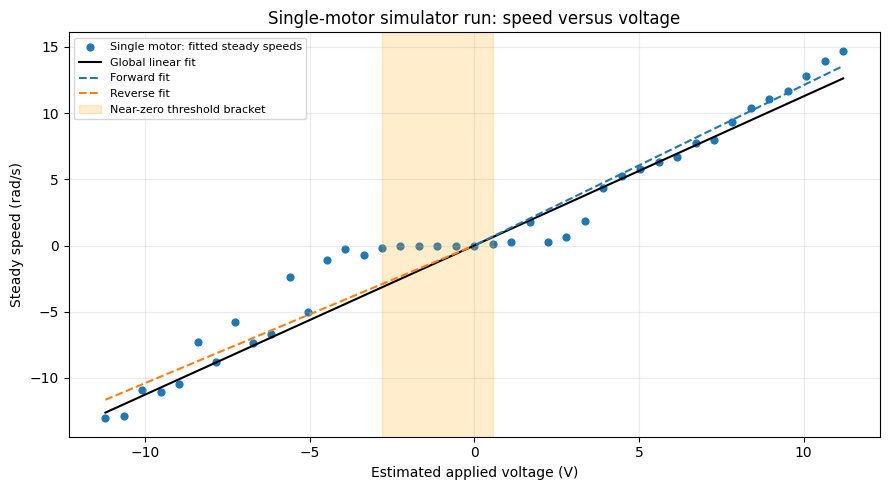

In [4]:
valid = results[(results.Status=='fit') & (results.PWM.abs()>=20)]
def constant_fit(g):
    u=g.Voltage_V.to_numpy(); w=g.omega_ss_rad_s.to_numpy()
    assert len(g)>=2
    gain=np.dot(u,w)/np.dot(u,u)
    return gain,1/gain,np.sqrt(np.mean((w-gain*u)**2))
summary=[]
for label,g in [('Both directions',valid),('Forward',valid[valid.PWM>0]),('Reverse',valid[valid.PWM<0])]:
    gain,ke,error=constant_fit(g)
    summary.append(dict(Direction=label,Gain_rad_s_V=gain,k_e_V_s_rad=ke,Speed_RMSE_rad_s=error))
constants=pd.DataFrame(summary)
print(constants.round(6).to_string(index=False))
stationary=results[results.Status=='no resolved motion']
moving=results[results.Status!='no resolved motion']
print("\nPWM with no resolved motion:",stationary.PWM.tolist())
neg=moving[moving.PWM<0].Voltage_V.max()
pos=moving[moving.PWM>0].Voltage_V.min()
print(f"Nearest moving voltages: {neg:.3f} V and {pos:.3f} V")
fig,ax=plt.subplots(figsize=(9,5))
ax.scatter(results.Voltage_V,results.omega_ss_rad_s,label='Single motor: fitted steady speeds',s=24)
x=np.linspace(results.Voltage_V.min(),results.Voltage_V.max(),200)
ax.plot(x,constants.iloc[0].Gain_rad_s_V*x,label='Global linear fit',color='black')
for i,label in [(1,'Forward'),(2,'Reverse')]:
    xx=x[x>=0] if i==1 else x[x<=0]
    ax.plot(xx,constants.iloc[i].Gain_rad_s_V*xx,'--',label=label+' fit')
ax.axvspan(neg,pos,color='orange',alpha=.2,label='Near-zero threshold bracket')
ax.set(xlabel='Estimated applied voltage (V)',ylabel='Steady speed (rad/s)',title='Single-motor simulator run: speed versus voltage')
ax.grid(alpha=.25);ax.legend(fontsize=8);fig.tight_layout();plt.show()


## 3. Compare the recorded angle with a numerical simulation

At +50% PWM, use the fitted $T_m$ and $\omega_{ss}$ in $d\omega/dt=(\omega_{ss}-\omega)/T_m$ and $d\theta/dt=\omega$. Integrate from rest, then overlay the simulated angle with the recorded angle. Also show the prediction from the **global** $k_e$; this distinguishes an excellent per-step fit from the limitations of one voltage–speed constant across all powers. Reusing the fitting data checks consistency, not independent predictive accuracy.


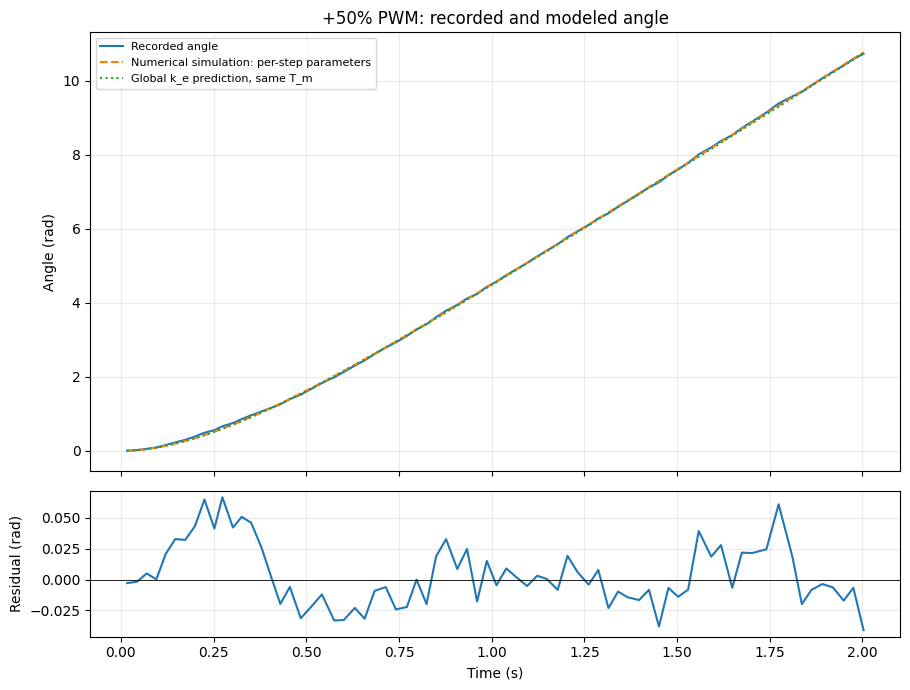

At +50%: U=5.600 V, omega_ss=6.322590 rad/s, T_m=0.299147 s, angle RMSE=0.025179 rad
Global k_e predicts 6.306245 rad/s at this voltage.
Numerical versus analytical maximum difference: 4.88e-10 rad


In [5]:
pwm=50
r=results.set_index('PWM').loc[pwm]
t,theta=traces[pwm]
assert r.Status=='fit'
tau=float(r.T_m_s); speed=float(r.omega_ss_rad_s)
sol=solve_ivp(lambda time,state:[(speed-state[0])/tau,state[0]],
    (0,float(t[-1])),[0,0],dense_output=True,rtol=1e-9,atol=1e-11)
simulated=sol.sol(t)[1]
max_error=np.max(np.abs(simulated-angle_model(t,speed,tau)))
assert max_error<1e-6
ke=float(constants.iloc[0].k_e_V_s_rad)
global_speed=float(r.Voltage_V)/ke
fig,axes=plt.subplots(2,1,figsize=(9,7),sharex=True,gridspec_kw={'height_ratios':[3,1]})
axes[0].plot(t,theta,label='Recorded angle')
axes[0].plot(t,simulated,'--',label='Numerical simulation: per-step parameters')
axes[0].plot(t,angle_model(t,global_speed,tau),':',label='Global k_e prediction, same T_m')
axes[0].set(ylabel='Angle (rad)',title='+50% PWM: recorded and modeled angle')
axes[0].legend(fontsize=8)
axes[1].plot(t,theta-simulated);axes[1].axhline(0,color='black',lw=.6)
axes[1].set(xlabel='Time (s)',ylabel='Residual (rad)')
for ax in axes:ax.grid(alpha=.25)
fig.tight_layout();plt.show()
print(f"At +50%: U={r.Voltage_V:.3f} V, omega_ss={speed:.6f} rad/s, T_m={tau:.6f} s, angle RMSE={r.RMSE_rad:.6f} rad")
print(f"Global k_e predicts {global_speed:.6f} rad/s at this voltage.")
print(f"Numerical versus analytical maximum difference: {max_error:.3g} rad")


## 4. Discussion — six sentences

This single-motor simulator dataset contains 2,971 readings across all 41 PWM settings, and its median per-step sampling intervals range from 26.26 to 28.27 ms rather than the requested 5 ms. The origin-constrained voltage–speed fit gives an effective $k_e=0.88801$ V·s/rad, with forward and reverse values of 0.82629 and 0.96195, showing directional asymmetry within this one motor. No resolved motion occurs at PWM [-20, -15, -10, -5, 0]; the nearest moving levels are -2.80 and 0.56 V, so the near-zero threshold is only bracketed by the tested grid. At +50% PWM, the fitted time constant is 0.29915 s and angle RMSE is 0.02518 rad, but agreement on the same data does not independently validate the model. The configured 11.2 V supply, simulator origin, finite encoder resolution and variation of fitted parameters with power limit interpretation as physical motor calibration. A second wheel was not measured, so wheel-to-wheel differences cannot be quantified; in a real robot, unequal wheel speeds can cause turning and errors in a motion predictor, while encoder odometry additionally depends on wheel geometry and slip.

## Reusable thinking schema

- **Definition:** identification estimates a model from input and response.
- **Composition:** PWM and supply → estimated voltage; encoder and timestamps → angle curve.
- **Logic:** transient curvature estimates $T_m$; final slope estimates $\omega_{ss}$; voltage–speed slope estimates $1/k_e$.
- **Intuition:** accelerating toward a cruising speed.
- **Interaction:** input, load and friction influence response; motor mismatch influences motion.
- **Thinking model:** check data → convert units → fit → compare → state limits.
- **General pattern:** validate predictions with a new experiment before relying on them.

**Submission boundary:** this notebook covers the requested single-motor analysis. It does not establish that simulator data satisfy a requirement for physical robot measurements. Preserve the original TXT and the QRS alongside this notebook; the original course page also asks for per-level raw files, whereas this collector produced one consolidated raw log. Any later split files must be labeled derived, not original robot output.

The written discussion above describes the original uploaded run. If DATA_PATH or RUN_INDEX changes, recompute and revise that discussion to match the new outputs.


In [6]:
# Optional exports: run this cell when you want standalone tables and the original TXT.
results.to_csv('motor_parameters.csv',index=False)
constants.to_csv('motor_constants.csv',index=False)
Path('motor_single_voltage_original.txt').write_bytes(raw)
print('Saved parameter tables and an exact copy of the analyzed raw TXT.')


Saved parameter tables and an exact copy of the analyzed raw TXT.
